In [1]:
from pathlib import Path
DATA = Path.cwd().parent / "data"
PKL_DIR = DATA / "pickle"

---

In [2]:
import pickle

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from yellowbrick.classifier import ConfusionMatrix
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

In [3]:
with open(PKL_DIR / 'expressions.pkl', "rb") as f:
    (X_train, y_train, X_test, y_test) = pickle.load(f)

In [4]:
labels = ["Raiva", "Nojo", "Medo", "Felicidade", "Neutro", "Tristeza", "Surpresa"]

# Modelo Dummy (26.23%)

In [47]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](7,)","[0.13,0.02,0.14,...,0.18,0.16,0.11]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](7,)","[0,1,2,...,4,5,6]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,52
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [48]:
y_pred_baseline = baseline_model.predict(X_test)
porcentagem_corte = accuracy_score(y_test, y_pred_baseline)

print(f"Acurácia mínima aceitável é: {porcentagem_corte * 100:.2f}%")

Acurácia mínima aceitável é: 25.50%


# Modelo Naive Bayes (47.87%)

In [50]:
naive_classifier = GaussianNB()
naive_classifier.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](7,)","[3665., 414.,3796.,...,4861.,4377.,3057.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](7,)","[0.13,0.02,0.14,...,0.18,0.16,0.11]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](7,)","[0,1,2,...,4,5,6]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.03e-10
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,52
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](7, 52)","[[0. ,0.16,0.17,...,0.1 ,0. ,0. ], [0. ,0.25,0.23,...,0.1 ,0. ,0. ], [0. ,0.09,0.09,...,0.06,0. ,0. ], ..., [0. ,0.07,0.08,...,0.02,0. ,0. ], [0. ,0.11,0.11,...,0.03,0. ,0. ], [0. ,0.01,0.01,...,0.04,0. ,0. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](7, 52)","[[0. ,0.04,0.05,...,0.04,0. ,0. ], [0. ,0.08,0.08,...,0.03,0. ,0. ], [0. ,0.03,0.03,...,0.02,0. ,0. ], ..., [0. ,0.02,0.02,...,0.01,0. ,0. ], [0. ,0.03,0.03,...,0.01,0. ,0. ], [0. ,0. ,0. ,...,0.01,0. ,0. ]]"


In [51]:
y_pred_naive = naive_classifier.predict(X_test)
porcentagem_corte = accuracy_score(y_test, y_pred_naive)

print(f"Acurácia Naive Bayes: {porcentagem_corte * 100:.2f}%")

Acurácia Naive Bayes: 46.72%


0.4672227099795142

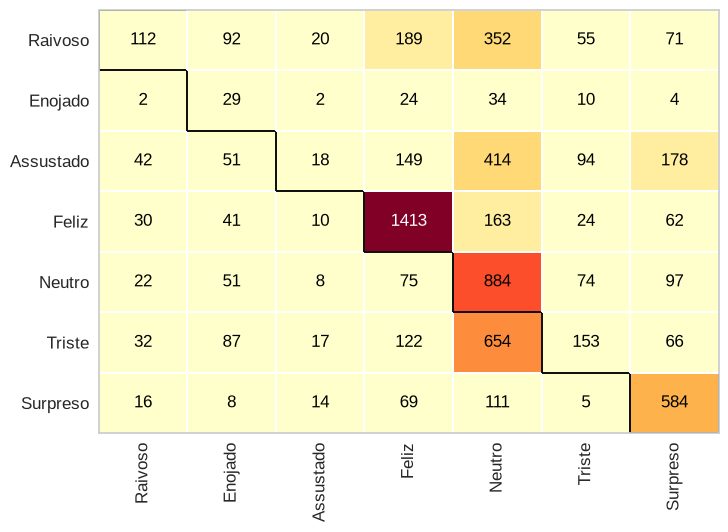

In [69]:
cm = ConfusionMatrix(naive_classifier, force_model=True, classes=labels)
cm.fit(X_train, y_train)
cm.score(X_test, y_test)

In [9]:
print(classification_report(y_test, y_pred_naive))

              precision    recall  f1-score   support

           0       0.46      0.12      0.19       817
           1       0.08      0.19      0.11        93
           2       0.27      0.03      0.06       889
           3       0.68      0.81      0.74      1684
           4       0.35      0.75      0.47      1160
           5       0.37      0.17      0.23      1019
           6       0.58      0.69      0.63       759

    accuracy                           0.48      6421
   macro avg       0.40      0.39      0.35      6421
weighted avg       0.47      0.48      0.43      6421



# Modelo de Árvore de Decisão (60.29% e 56.73%)

In [6]:
tree_classifier = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=42).fit(X_train, y_train)

KeyboardInterrupt: 

In [8]:
y_pred_randforest = tree_classifier.predict(X_test)
porcentagem_corte = accuracy_score(y_test, y_pred_randforest)

print(f"Acurácia Random Forest: {porcentagem_corte * 100:.2f}%")

Acurácia Random Forest: 61.97%


In [5]:
cm = ConfusionMatrix(tree_classifier, force_model=True)
cm.fit(X_train, y_train)
cm.score(X_test, y_test)

NameError: name 'tree_classifier' is not defined

In [10]:
print(classification_report(y_test, y_pred_randforest))

              precision    recall  f1-score   support

           0       0.61      0.45      0.52       865
           1       0.93      0.41      0.57       102
           2       0.55      0.36      0.44       939
           3       0.77      0.86      0.81      1729
           4       0.49      0.66      0.56      1194
           5       0.49      0.47      0.48      1116
           6       0.75      0.77      0.76       803

    accuracy                           0.62      6748
   macro avg       0.65      0.57      0.59      6748
weighted avg       0.62      0.62      0.61      6748



In [11]:
pickle.dump(tree_classifier,open(PKL_DIR/"rf.sav", "wb"))

In [13]:
hgb_classifier = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05)
hgb_classifier.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",300
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dt

In [14]:
y_pred_hgb = hgb_classifier.predict(X_test)

porcentagem_corte = accuracy_score(y_test, y_pred_hgb)

print(f"Acurácia HGB: {porcentagem_corte * 100:.2f}%")

Acurácia HGB: 61.25%


0.6124777711914642

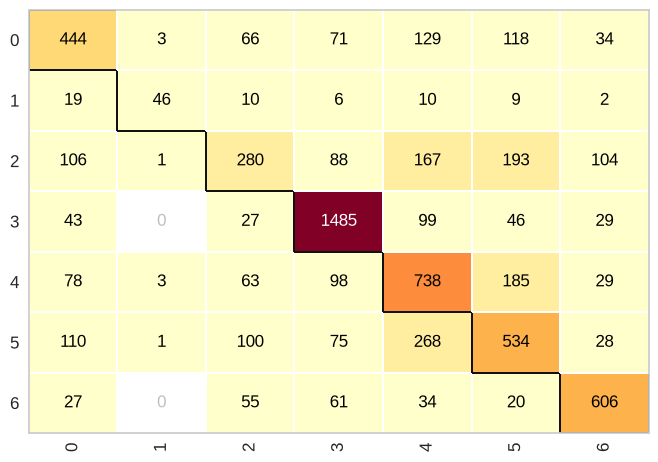

In [15]:
cm = ConfusionMatrix(hgb_classifier, force_model=True)
cm.fit(X_train, y_train)
cm.score(X_test, y_test)

In [16]:
print(classification_report(y_test, y_pred_hgb))

              precision    recall  f1-score   support

           0       0.54      0.51      0.52       865
           1       0.85      0.45      0.59       102
           2       0.47      0.30      0.36       939
           3       0.79      0.86      0.82      1729
           4       0.51      0.62      0.56      1194
           5       0.48      0.48      0.48      1116
           6       0.73      0.75      0.74       803

    accuracy                           0.61      6748
   macro avg       0.62      0.57      0.58      6748
weighted avg       0.61      0.61      0.60      6748



In [17]:
pickle.dump(hgb_classifier,open(PKL_DIR/"hgb.sav", "wb"))

# Rede Neural

In [14]:
mlp_classifier = MLPClassifier(verbose=True, hidden_layer_sizes=(100, 50))
mlp_classifier.fit(X_train, y_train)

Iteration 1, loss = 1.46589944
Iteration 2, loss = 1.25517834
Iteration 3, loss = 1.22680981
Iteration 4, loss = 1.21270637
Iteration 5, loss = 1.20161129
Iteration 6, loss = 1.19587422
Iteration 7, loss = 1.18821569
Iteration 8, loss = 1.18138412
Iteration 9, loss = 1.17813758
Iteration 10, loss = 1.17194355
Iteration 11, loss = 1.16689176
Iteration 12, loss = 1.16306963
Iteration 13, loss = 1.15895808
Iteration 14, loss = 1.15697695
Iteration 15, loss = 1.15268606
Iteration 16, loss = 1.14922472
Iteration 17, loss = 1.14792518
Iteration 18, loss = 1.14469552
Iteration 19, loss = 1.14072997
Iteration 20, loss = 1.13889346
Iteration 21, loss = 1.13639370
Iteration 22, loss = 1.13326059
Iteration 23, loss = 1.13050067
Iteration 24, loss = 1.12752996
Iteration 25, loss = 1.12664405
Iteration 26, loss = 1.12374185
Iteration 27, loss = 1.12210199
Iteration 28, loss = 1.11999248
Iteration 29, loss = 1.11724799
Iteration 30, loss = 1.11600036
Iteration 31, loss = 1.11347786
Iteration 32, los

/home/bruno-custodio/Documentos/Scripts/Repositórios/reconhecedor-de-humor/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [15]:
y_pred_neural = mlp_classifier.predict(X_test)

porcentagem_corte = accuracy_score(y_test, y_pred_neural)

print(f"Acurácia Rede Neural: {porcentagem_corte * 100:.2f}%")

Acurácia Rede Neural: 55.72%


0.557234075689145

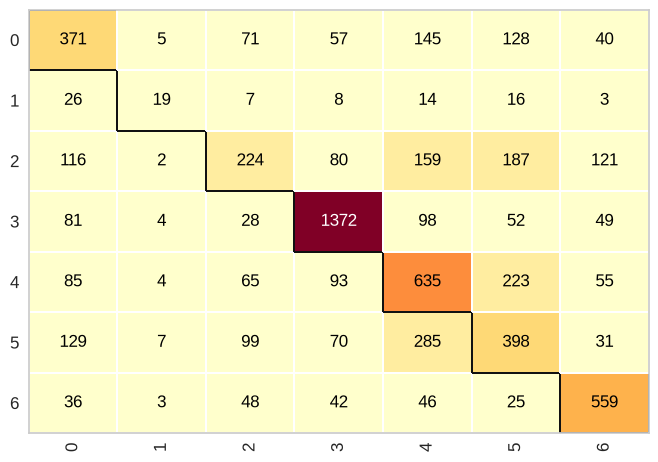

In [16]:
cm = ConfusionMatrix(mlp_classifier, force_model=True)
cm.fit(X_train, y_train)
cm.score(X_test, y_test)

In [17]:
print(classification_report(y_test, y_pred_neural))

              precision    recall  f1-score   support

           0       0.44      0.45      0.45       817
           1       0.43      0.20      0.28        93
           2       0.41      0.25      0.31       889
           3       0.80      0.81      0.81      1684
           4       0.46      0.55      0.50      1160
           5       0.39      0.39      0.39      1019
           6       0.65      0.74      0.69       759

    accuracy                           0.56      6421
   macro avg       0.51      0.49      0.49      6421
weighted avg       0.55      0.56      0.55      6421



# ENSEMBLE

In [ ]:
rf = pickle.load(open(PKL_DIR / "rf.sav", "rb"))
hgb = pickle.load(open(PKL_DIR / "hgb.sav", "rb"))

In [ ]:
ens = VotingClassifier([("rf", rf), ("hgb", hgb)], voting="soft")
ens.fit(X_train, y_train)

In [13]:
y_pred_ens = ens.predict(X_test)

porcentagem_corte = accuracy_score(y_test, y_pred_ens)

print(f"Acurácia Ensemble: {porcentagem_corte * 100:.2f}%")

Acurácia Ensemble: 63.49%


0.6348547717842323

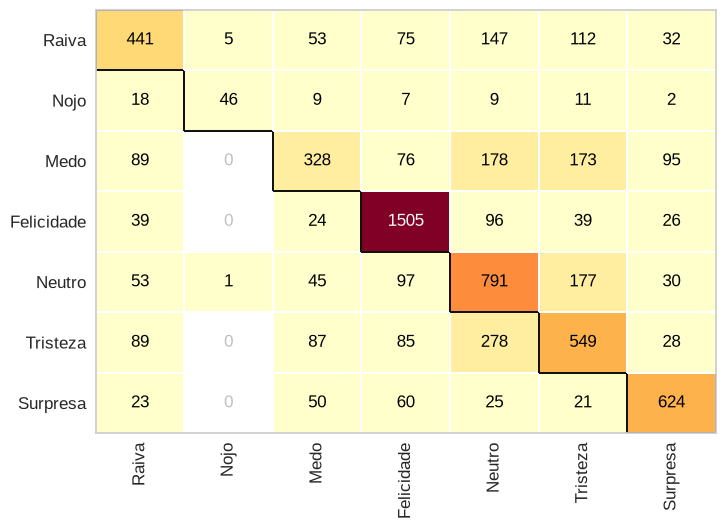

In [16]:
cm = ConfusionMatrix(ens, force_model=True, classes=labels)
cm.fit(X_train, y_train)
cm.score(X_test, y_test)

In [15]:
print(classification_report(y_test, y_pred_ens))

              precision    recall  f1-score   support

           0       0.59      0.51      0.55       865
           1       0.88      0.45      0.60       102
           2       0.55      0.35      0.43       939
           3       0.79      0.87      0.83      1729
           4       0.52      0.66      0.58      1194
           5       0.51      0.49      0.50      1116
           6       0.75      0.78      0.76       803

    accuracy                           0.63      6748
   macro avg       0.65      0.59      0.61      6748
weighted avg       0.63      0.63      0.63      6748



In [ ]:
pickle.dump(ens,open(PKL_DIR/"ensemble.sav", "wb"))

In [5]:
rf = pickle.load(open(PKL_DIR/"rf.sav", "rb"))
print(type(rf))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
